# GPUs in Space, Part 2: What would have to be true?

[Part 1](https://goodatinvesting.com/website/gpus-in-space/) (`space_gpu_datacenter.ipynb`) sized a 200 MW orbital LLM-inference fleet at 7,000 km: **1,750 satellites and a \$37B "space premium"**, meaning the cost on top of the GPUs you would buy anyway on the ground.

Part 2 asks the follow-up question: **at what point does this become viable?** It works through it in order:

1. **What "\$ per watt" means for solar power**, and why quoted prices run from \$0.05/W to \$450/W (Section 1).
2. **Where Part 1's \$37B actually went**, broken down by subsystem (Section 2).
3. **A best-case orbit**: 550 km dawn-dusk sun-synchronous (Section 3).
4. **A best-case satellite** with optimistic solar arrays and Starship launch (Sections 4–5).
5. **The staircase from Part 1 to the best case**, and how it compares with a ground datacenter (Section 6).
6. **What would have to be true**: break-even array prices across launch costs (Sections 7–8).
7. **Fitting it into Starship** (Section 9).

### The optimism principle
Every assumption takes the **most optimistic end of its cited range** (tagged `[OPT]` in the assumptions cell). Pessimistic values appear only as sensitivities. The point of the exercise is to say: *even if everything goes right, here is what still has to be true.*

Research notes and sources: `research/part2_research.md`. Plan: `PART2_PLAN.md`.

## How to read the units in this notebook

Space-power discussions mix a handful of units that sound alike but measure different things. Here they are in plain English:

| Unit | What it measures | Everyday anchor |
|---|---|---|
| **W** (watt) | Power: a *rate* of energy flow at one instant | An LED bulb ≈ 10 W; a microwave ≈ 1,000 W |
| **kW / MW** | 1,000 W / 1,000,000 W | A US home averages ≈ 1.2 kW. One GPU rack (NVL72) ≈ 120 kW. Our fleet: 200 MW ≈ a small power plant |
| **kWh** | Energy = power × time | What your electric bill counts. A 1 kW heater running for 1 hour = 1 kWh |
| **\$/W** | Purchase price ÷ *rated* power | A "\$1/W" 400 W panel costs \$400. **It says nothing about how many hours the panel will actually produce**, which is a major source of confusion (see 1.2) |
| **W/kg** | Rated power ÷ mass (higher = lighter) | A rooftop panel ≈ 20 W/kg. Good space arrays ≈ 100–200 W/kg |
| **W/m²** | Rated power ÷ area | Sets how big the array is |
| **\$/kg** | Launch price per kilogram delivered to orbit | Falcon 9 today ≈ \$2,500–4,000/kg; Starship goal ≈ \$100/kg |
| **\$/kW-yr** | Dollars to keep 1 kW of computing running for one year | **The yardstick for comparing space against the ground.** It puts a one-time purchase (satellite + launch, spread over its life) on the same footing as an ongoing bill (electricity) |
| **rad / krad** | Radiation dose absorbed by electronics | Sets whether chips and solar cells survive the orbit |

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# ---- Physical constants (identical to Part 1) ----
SIGMA = 5.670374419e-8    # Stefan–Boltzmann constant [W / m^2 / K^4]
SOLAR_CONSTANT = 1361.0   # Solar irradiance at 1 AU [W/m^2]
R_EARTH = 6_371_000.0     # Earth mean radius [m]
MU_EARTH = 3.986004418e14 # Earth's gravitational parameter [m^3/s^2]
G0 = 9.80665              # Standard gravity [m/s^2]
J2 = 1.08263e-3           # Earth oblateness term (for sun-synchronous inclination)
OBLIQUITY_DEG = 23.44     # Tilt of Earth's axis vs. its orbit around the Sun

# ---- Chart style: reference palette, fixed slot order, recessive grid ----
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2.0, "font.size": 10,
    "legend.frameon": False, "text.parse_math": False,
})

## Centralized assumptions

All editable inputs live in the next cell. Tags:
- `[OPT]`: a deliberately optimistic pick (the optimism principle).
- `[P1]`: carried over unchanged from Part 1, for continuity.
- `[EST]`: my own estimate with no direct source. **Verify before publishing.**

In [2]:
# =============================================================================
# CENTRALIZED ASSUMPTIONS — Part 2
# =============================================================================

# ==== Compute payload (unchanged from Part 1) ====
N_GPUS = 72                        # [P1] GB200 NVL72-class module
P_COMPUTE_KW = 120.0               # [P1] module electrical power [kW]
OVERHEAD_FRAC = 0.10               # [P1] spacecraft overhead (comms, attitude control, power conditioning)
M_COMPUTE_KG = 750.0               # [P1] space-optimized compute module mass [kg]
COMPUTE_COST_PER_KW = 22_500.0     # [P1] $/kW. Paid on Earth too, so EXCLUDED from the space premium.

# ==== Thermal (unchanged from Part 1) ====
T_GPU_C = 90.0                     # [P1]
DELTA_T_TO_RADIATOR_C = 30.0       # [P1]
EPSILON = 0.90                     # [P1]
ALPHA_SOLAR = 0.20                 # [P1]
ALPHA_IR = 0.90                    # [P1]
T_SINK_K = 3.0                     # [P1]
K_EFFECTIVE = 0.90                 # [P1]
EARTH_IR_FLUX_W_PER_M2 = 234.0     # [P1]
EARTH_BOND_ALBEDO = 0.294          # [P1]
EARTH_VIEW_FRACTION_OF_MAX = 0.10  # [P1]
RADIATOR_SOLAR_VIEW_FACTOR = 0.02  # [P1]
ALBEDO_GEOMETRY_FACTOR = 0.50      # [P1]
RADIATOR_AREAL_DENSITY = 2.0       # [P1][OPT] kg/m², now read as INCLUDING pumps/plumbing.
                                   #   A pumped-loop deployable radiator thesis reports ~1.9 kg/m² for the
                                   #   whole system; Redwire Q-Rad panels list 3.5–4.9 kg/m².
RADIATOR_COST_PER_M2 = 2_000.0     # [P1] placeholder

# ==== Solar array: default = optimistic tier ====
# All space-array $/W and W/kg values are per watt at beginning of life, measured
# in space sunlight (AM0, 1361 W/m²). See Section 1 for what that means.
ARRAY_SPECIFIC_POWER_W_PER_KG = 200.0  # [OPT] Solestial's 2023 SBIR *target*; flown roll-out arrays are 100–120.
ARRAY_POWER_DENSITY_W_PER_M2 = 400.0   # [P1]
ARRAY_COST_PER_W = 10.0                # [OPT] Between Starpath's $11.20/W flight panel and Mach33's $9/W
                                       #   thin-PV assumption. Part 1 used $50/W; Solestial targets $40/W.
ARRAY_DEGRADATION_PER_YR = 0.01        # [OPT][EST] 1%/yr power loss at 550 km (annealing silicon).
ROOFTOP_ARRAY_COST_PER_W = 0.11        # Bookend: global wholesale rooftop module price (OPIS/InfoLink, Jul 2026), see 1.4

# ==== Satellite bus ====
BUS_MASS_FRACTION_OF_TOTAL = 0.25      # [P1] The SolidWorks model will replace this flat fraction.
BUS_COST_FIXED = 500_000.0             # [P1] $ per satellite

# ==== Orbit: 550 km dawn-dusk sun-synchronous ====
ALT_KM = 550.0
LTAN_HOURS = 18.0                      # local time of ascending node: 18:00 = dawn-dusk

# ==== Station-keeping (drag) ====
ATM_DENSITY_KG_M3 = 3e-13              # [EST] near solar maximum at 550 km; solar minimum is ~10× lower
DRAG_CD = 2.2                          # typical flat-plate drag coefficient
FRONTAL_AREA_EDGE_ON_M2 = 15.0         # [OPT][EST] arrays and radiators fly edge-on to the velocity (Section 3.3)
EP_ISP_S = 1_500.0                     # Hall-effect electric thruster

# ==== Launch: Starship ====
LAUNCH_COST_PER_KG = 100.0             # [OPT] ≈ Musk's ~$10M/flight goal. Suncatcher projects <$200/kg by ~2035.
STARSHIP_PAYLOAD_LEO_T = 150.0         # [OPT] reusable; SpaceX states ">100 t", V3 claims ~200 t
STARSHIP_BAY_VOLUME_M3 = 1_000.0       # [OPT] the original goal; listed figure is ~614 m³ (used once CAD exists)
APPLY_SSO_PAYLOAD_PENALTY = False      # [OPT] True = also charge for Starship carrying less to a polar orbit
SHIP_DRY_T = 120.0                     # [EST] Starship upper-stage dry mass, used only for the penalty estimate
SHIP_PROP_T = 1_600.0                  # [EST] upper-stage propellant load
SHIP_ISP_VAC_S = 380.0                 # [EST] Raptor vacuum
LAUNCH_SITE_LAT_DEG = 26.0             # Starbase, Texas

# ==== Economics ====
SATELLITE_LIFE_YR = 5.0                # matches the GPU refresh cycle (and Suncatcher's assumption)
TARGET_AVG_COMPUTE_MW = 200.0          # [P1] fleet size
TERRESTRIAL_BUILD_COST_PER_MW = 20e6   # [OPT for space] AI-ready build, excluding IT and land. Shell & core
                                       #   averages $10.7–11.7M/MW (JLL, Cushman & Wakefield).
TERRESTRIAL_BUILD_AMORTIZATION_YR = 5  # [OPT for space] A building really lasts 15–20 yr. Charging it all to
                                       #   one 5-year GPU generation makes the ground look as expensive as possible.
TERRESTRIAL_ENERGY_COST_PER_KW_YR = 1_500.0  # middle of Suncatcher's $570–3,000/kW-yr ($0.06–0.25/kWh, PUE 1.09–1.4)
TERRESTRIAL_ENERGY_RANGE_PER_KW_YR = (570.0, 3_000.0)
TERRESTRIAL_REALISTIC_BUILD_COST_PER_MW = 11.7e6  # Cushman & Wakefield 2025 US average (shell & core, excl. IT)
TERRESTRIAL_REALISTIC_AMORTIZATION_YR = 15       # a building hosts ~3 GPU generations

# ==== Solar explainer inputs (Section 1) ====
AM0_TO_STC_POWER_RATIO = 1.25          # [EST] 1 W rated on Earth (STC) ≈ 1.25 W in space sunlight
HOUSE_KWH_PER_W_PER_YR = 1.4           # [EST] US-average rooftop yield (~16% capacity factor)
HOUSE_PANEL_LIFE_YR = 25
HOUSE_PANEL_W_PER_KG = 20.0            # [EST] ~450 W module weighing ~22 kg (glass + aluminum frame)

---
## 1. Why "one watt" of solar can cost \$0.05 or \$450

If you have priced rooftop solar, space array prices look absurd: hundreds of dollars per watt against a dollar or two. Both numbers are real. They differ for four reasons, and each one is a place where intuition from your house breaks down:

1. **What's included.** A bare cell, a framed module, an installed rooftop system, or a deployable flight wing.
2. **Which watt.** Ratings are measured under a *standard* light, and the standard differs on Earth and in space.
3. **How much energy each watt produces.** A watt on a roof works a few hours a day. A watt in the right orbit works almost all the time.
4. **Weight and the environment.** Space arrays must be light (every kilogram costs launch money) and survive radiation, vacuum, and temperature swings, all without a repair visit.

### 1.1 Which watt? Ratings are measured under a standard light

A solar "watt" is not measured in your backyard. It is the power produced under an agreed test light:

| | Rooftop panel ("Wp", watts-peak) | Space array |
|---|---|---|
| Standard | **STC**: Standard Test Conditions | **AM0**: Air Mass Zero |
| Light intensity | 1,000 W/m² | **1,361 W/m²**, sunlight before the atmosphere absorbs any |
| Spectrum | AM1.5: sunlight after passing through 1.5 atmospheres | Raw sunlight in space |
| Cell temperature | 25 °C | ~28 °C |

The same cell rates **roughly 25% more watts in space**, simply because the light is brighter. That is a small effect next to everything else here, but it means a "\$/W" quoted for a rooftop panel and one quoted for a satellite array aren't measured in exactly the same watts.

### 1.2 How much energy does one rated watt produce?

This is the difference that matters most and is least intuitive. **\$/W is a price for capacity, not for energy.** A rooftop watt delivers energy only when the sun is up, high, and not behind clouds. A watt on a satellite in a dawn-dusk orbit faces the sun about 95% of the time, always head-on, in light ~36% brighter than on the ground.

In [3]:
house_kwh_per_w_yr = HOUSE_KWH_PER_W_PER_YR
house_capacity_factor = house_kwh_per_w_yr / 8.760

# Dawn-dusk 550 km orbit: sunlit ~95% averaged over the year (computed exactly in Section 3).
space_sunlit_fraction_preview = 0.95
space_kwh_per_wAM0_yr = 8.760 * space_sunlit_fraction_preview          # per space-rated watt
space_kwh_per_wSTC_yr = space_kwh_per_wAM0_yr * AM0_TO_STC_POWER_RATIO # same cell, rated on Earth

print("Energy produced per rated watt per year")
print(f"  Rooftop (US average):            {house_kwh_per_w_yr:5.1f} kWh/W/yr   (capacity factor {house_capacity_factor:.0%})")
print(f"  Same cell, dawn-dusk 550 km:     {space_kwh_per_wSTC_yr:5.1f} kWh/W/yr   (capacity factor ~{space_sunlit_fraction_preview:.0%}, brighter light)")
print(f"  Ratio:                           {space_kwh_per_wSTC_yr/house_kwh_per_w_yr:5.1f}x")

Energy produced per rated watt per year
  Rooftop (US average):              1.4 kWh/W/yr   (capacity factor 16%)
  Same cell, dawn-dusk 550 km:      10.4 kWh/W/yr   (capacity factor ~95%, brighter light)
  Ratio:                             7.4x


**Takeaway:** a solar cell in the right orbit produces roughly **7× more energy per year** than the same cell on a roof. This is the core of the case for space solar, and it matches Google's "up to 8×" claim for Project Suncatcher.

Keep this in mind when comparing \$/W figures. A space array can cost several times more per watt than a rooftop panel and still produce energy at a similar cost per kWh. It cannot cost *hundreds* of times more.

### 1.3 The price ladder: what each quoted "\$/W" includes

Each rung below is a real quoted figure. They span **nearly 10,000×**, because each one includes a different slice of the work.

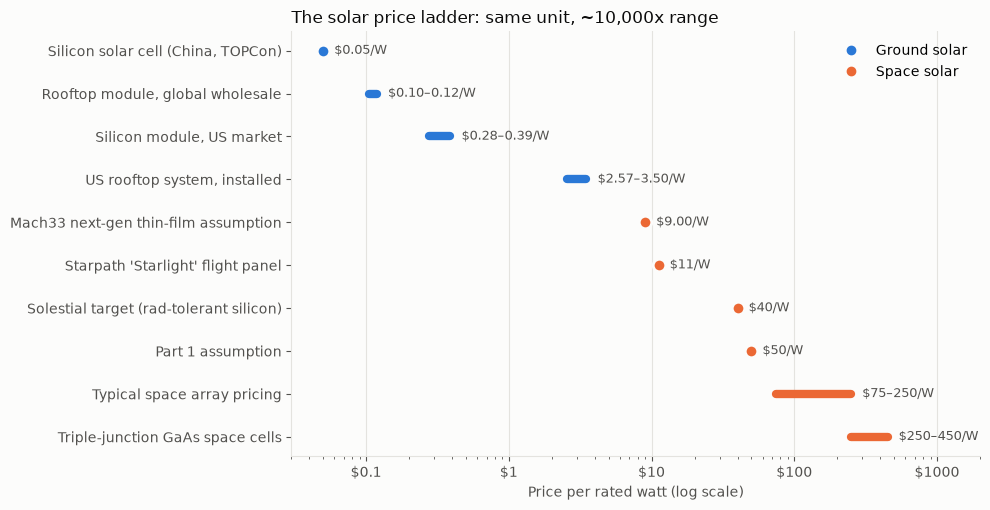

,Item,Low $/W,High $/W,What's included,Source
0,"Silicon solar cell (China, TOPCon)",0.05,0.05,"bare cell, no glass or frame","pv magazine, May 2026"
1,"Rooftop module, global wholesale",0.10,0.12,cells + glass + frame + junction box,"OPIS / InfoLink, Jul 2026"
2,"Silicon module, US market",0.28,0.39,"module, US prices (tariffs)",Surrey review / Anza Q4 2025
3,"US rooftop system, installed",2.57,3.50,modules + inverter + racking + labor + permits,EnergySage H1 2026; LBNL
4,Mach33 next-gen thin-film assumption,9.00,9.00,space array (analyst assumption),Mach33 via secondary
5,Starpath 'Starlight' flight panel,11.20,11.20,space-rated silicon panel,Starpath / TechCrunch 2025
6,Solestial target (rad-tolerant silicon),40.00,40.00,complete 50 kW-class wing (target),NASA SBIR 2023
7,Part 1 assumption,50.00,50.00,complete wing,Part 1
8,Typical space array pricing,75.00,250.00,"complete flight wing, multi-junction",Starpath / TechCrunch 2025
9,Triple-junction GaAs space cells,250.00,450.00,bare cells only,"Surrey review, Acta Astronautica 2026"


In [4]:
# (label, low $/W, high $/W, what it includes, source)
price_ladder = [
    ("Silicon solar cell (China, TOPCon)",          0.05,  0.05,  "bare cell, no glass or frame",                    "pv magazine, May 2026"),
    ("Rooftop module, global wholesale",            0.104, 0.119, "cells + glass + frame + junction box",            "OPIS / InfoLink, Jul 2026"),
    ("Silicon module, US market",                   0.275, 0.39,  "module, US prices (tariffs)",                     "Surrey review / Anza Q4 2025"),
    ("US rooftop system, installed",                2.57,  3.50,  "modules + inverter + racking + labor + permits",  "EnergySage H1 2026; LBNL"),
    ("Mach33 next-gen thin-film assumption",        9.0,   9.0,   "space array (analyst assumption)",                "Mach33 via secondary"),
    ("Starpath 'Starlight' flight panel",           11.2,  11.2,  "space-rated silicon panel",                       "Starpath / TechCrunch 2025"),
    ("Solestial target (rad-tolerant silicon)",     40.0,  40.0,  "complete 50 kW-class wing (target)",              "NASA SBIR 2023"),
    ("Part 1 assumption",                           50.0,  50.0,  "complete wing",                                   "Part 1"),
    ("Typical space array pricing",                 75.0,  250.0, "complete flight wing, multi-junction",            "Starpath / TechCrunch 2025"),
    ("Triple-junction GaAs space cells",            250.0, 450.0, "bare cells only",                                 "Surrey review, Acta Astronautica 2026"),
]
ladder = pd.DataFrame(price_ladder, columns=["Item", "Low $/W", "High $/W", "What's included", "Source"])
ladder["Mid $/W"] = np.sqrt(ladder["Low $/W"] * ladder["High $/W"])

fig, ax = plt.subplots(figsize=(10, 5.2))
y = np.arange(len(ladder))[::-1]
is_space = ladder["What's included"].str.contains("space|wing|flight|cells only|Part")
for yi, (_, r), space in zip(y, ladder.iterrows(), is_space):
    color = SERIES[1] if space else SERIES[0]
    if r["High $/W"] > r["Low $/W"]:
        ax.plot([r["Low $/W"], r["High $/W"]], [yi, yi], color=color, lw=6, solid_capstyle="round")
    else:
        ax.plot(r["Mid $/W"], yi, "o", color=color, ms=9, mec="#fcfcfb", mew=2)
    fmt = lambda v: f"{v:,.2f}" if v < 10 else f"{v:,.0f}"
    label = f"${fmt(r['Low $/W'])}"
    if r["High $/W"] > r["Low $/W"]:
        label += f"–{fmt(r['High $/W'])}"
    ax.annotate(label + "/W", (r["High $/W"], yi), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
ax.set_xscale("log")
ax.set_xlim(0.03, 2_000)
ax.set_yticks(y, ladder["Item"])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:g}"))
ax.set_xlabel("Price per rated watt (log scale)")
ax.set_title("The solar price ladder: same unit, ~10,000x range", loc="left")
ax.plot([], [], "o", color=SERIES[0], label="Ground solar")
ax.plot([], [], "o", color=SERIES[1], label="Space solar")
ax.legend(loc="upper right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

display(ladder[["Item", "Low $/W", "High $/W", "What's included", "Source"]])

#### What sits between a \$0.05 cell and a \$40–250 flight wing

Here is each layer of a space array next to its rooftop equivalent. **No layer-by-layer price breakdown for space arrays has been published**, so this table shows *where* the money goes without inventing numbers for each layer.

| Layer | On your roof | On a satellite | Why the space version costs more |
|---|---|---|---|
| **1. Photovoltaic cells** | Silicon, ~\$0.05/W | Usually triple-junction GaAs (\$250–450/W); Starlink-style designs use silicon | GaAs cells are more efficient and radiation-hard, but are made in tiny volumes on costly germanium wafers |
| **2. Front protection** | 3.2 mm tempered glass sheet, heavy and cheap | Thin (~0.1 mm) cerium-doped **coverglass bonded cell by cell** | Blocks radiation and UV. The Surrey review finds coverglass is **the largest cost in a silicon space array** |
| **3. Wiring** | Soldered ribbons and a junction box | Welded interconnects, bypass diodes, and a harness built to survive tens of thousands of hot–cold cycles | No repair visit is possible |
| **4. Backing structure** | Aluminum frame, ~20 W/kg | Kapton blanket or composite panel, 100–200 W/kg | Getting 10× lighter means exotic materials and careful handling |
| **5. Deployment** | Installer bolts it to a rack | Booms, hinges, and tensioning that unfold once, unattended, after launch shaking | A failed deployment loses the whole satellite |
| **6. Pointing and power transfer** | Fixed tilt | Solar array drive with rotating electrical joints (slip rings) | In a dawn-dusk orbit the Sun barely moves relative to the satellite, so this can be simple |
| **7. Testing and qualification** | One certification per product line | Thermal vacuum, radiation, vibration, and acoustic tests, plus lot acceptance | Small production runs carry the full test cost |
| **8. Volume** | Hundreds of gigawatts made per year | A tiny fraction of that | No economies of scale, yet |

### 1.4 A bookend: what if a space array cost what rooftop solar costs?

To see how far array prices would have to fall, this notebook carries one deliberately extreme case: **a whole deployed space wing priced like a wholesale rooftop module, about \$0.11/W**. It is not a real product. It's a lower bound that answers "if the array were nearly free, what would still stand in the way?"

How far is that from today?

- **Cells are already there.** Silicon cells cost ~\$0.05/W, and some low-cost space-array concepts (Starlink-style) aim to use high-volume terrestrial-grade silicon rather than space-grade GaAs.
- **The rest of the wing is not.** A \$0.11/W wing is ~100× below today's cheapest flight panel (\$11.20/W) and ~360× below Solestial's target. Layers 2–8 in the table above would all have to fall the way rooftop modules did over two decades. Nobody has published a path to this.

### 1.5 Two ways to turn \$/W into something comparable

- **Launch cost per watt** = launch \$/kg ÷ array W/kg. This is how mass becomes money.
- **Array cost per kWh it will ever produce** = \$/W ÷ (kWh produced per W per year × years of life). This compares the array with a power bill.

In [5]:
house_installed_per_w = 2.57
house_lifetime_kwh_per_w = HOUSE_KWH_PER_W_PER_YR * HOUSE_PANEL_LIFE_YR
space_lifetime_kwh_per_w = space_kwh_per_wAM0_yr * SATELLITE_LIFE_YR * (1 - ARRAY_DEGRADATION_PER_YR * SATELLITE_LIFE_YR / 2)

rows = [
    ("Rooftop system, installed",              house_installed_per_w, None,                     house_lifetime_kwh_per_w),
    ("Rooftop module, launched to space",      0.11,  HOUSE_PANEL_W_PER_KG,                     space_lifetime_kwh_per_w),
    ("Space array at rooftop price ($0.11/W)", ROOFTOP_ARRAY_COST_PER_W, ARRAY_SPECIFIC_POWER_W_PER_KG,            space_lifetime_kwh_per_w),
    ("Space array, optimistic default",        ARRAY_COST_PER_W, ARRAY_SPECIFIC_POWER_W_PER_KG, space_lifetime_kwh_per_w),
    ("Space array, Solestial target",          40.0,  200.0,                                    space_lifetime_kwh_per_w),
    ("Space array, roll-out GaAs (ROSA-class)",100.0, 110.0,                                    space_lifetime_kwh_per_w),
]
out = []
for name, price, w_per_kg, kwh in rows:
    launch_per_w = (LAUNCH_COST_PER_KG / w_per_kg) if w_per_kg else 0.0
    total_per_w = price + launch_per_w
    out.append({
        "Option": name,
        "Hardware $/W": price,
        f"Launch $/W @ ${LAUNCH_COST_PER_KG:,.0f}/kg": launch_per_w,
        "Hardware + launch $/W": total_per_w,
        "Lifetime kWh per W": kwh,
        "Array $ per lifetime kWh": total_per_w / kwh,
    })
solar_compare = pd.DataFrame(out)
display(solar_compare)
print(f"For reference, US datacenter electricity is ~$0.06–0.25/kWh (Suncatcher §4.4).")
print(f"Space lifetime = {SATELLITE_LIFE_YR:.0f} yr; rooftop lifetime = {HOUSE_PANEL_LIFE_YR} yr.")
print("'Rooftop module launched to space' ignores that it would not survive (no radiation protection,")
print("outgassing, no deployment). It is there to show that at cheap launch, mass stops mattering.")

,Option,Hardware $/W,Launch $/W @ $100/kg,Hardware + launch $/W,Lifetime kWh per W,Array $ per lifetime kWh
0,"Rooftop system, installed",2.57,0.00,2.57,35.00,0.07
1,"Rooftop module, launched to space",0.11,5.00,5.11,40.57,0.13
2,Space array at rooftop price ($0.11/W),0.11,0.50,0.61,40.57,0.02
3,"Space array, optimistic default",10.00,0.50,10.50,40.57,0.26
4,"Space array, Solestial target",40.00,0.50,40.50,40.57,1.00
5,"Space array, roll-out GaAs (ROSA-class)",100.00,0.91,100.91,40.57,2.49


For reference, US datacenter electricity is ~$0.06–0.25/kWh (Suncatcher §4.4).
Space lifetime = 5 yr; rooftop lifetime = 25 yr.
'Rooftop module launched to space' ignores that it would not survive (no radiation protection,
outgassing, no deployment). It is there to show that at cheap launch, mass stops mattering.


**What this table shows:**
- At Starship-era launch prices, **launch adds only about \$0.50 per watt** to a 200 W/kg array. A 10× heavier rooftop module adds ~\$5/W. **Once launch is cheap, the array's purchase price dominates, not its weight.** This sharpens the Part 1 thesis: with cheap launch, solar arrays become a *parts-cost* problem.
- A space array lives ~5 years (the GPU refresh cycle), while a rooftop system lives ~25. So even though each space watt makes ~6× more energy per year, it gets only a fifth as many years to pay itself back.
- **At \$10/W, the array alone costs about as much per kWh as the *most expensive* datacenter grid power (\$0.25/kWh), before radiators, structure, launch, or the satellite itself.** At \$40/W it is ~4× that. At rooftop prices it is nearly free. That is the central tension of this notebook.

---
## 2. Where Part 1's \$37B actually went

Part 1 reported the space premium, but not *which subsystem* was responsible for it. Here it is broken down.

**Method.** A subsystem's true cost is its hardware price **plus** the launch cost of its mass **plus** its share of the bus. The bus was a flat 25% of total mass, so every kilogram of payload brought 1/0.75 = 1.33 kg to orbit. The values below are copied from Part 1's final scenario: 7,000 km, \$5,453/kg delivered, rerun on 2026-11-15.

,Subsystem,Mass kg,Hardware $M,Launch share $M,Total $M,Share of premium
0,Solar arrays,660.00,6.60,4.80,11.40,0.54
1,Compute (launch only),750.00,0.00,5.45,5.45,0.26
2,Radiators,475.71,0.48,3.46,3.93,0.18
3,Bus fixed cost,0.00,0.50,0.00,0.50,0.02


Per-satellite premium: $21.29M  (Part 1 reported $21.29M)
Fleet premium:         $37.25B (Part 1 reported $37.25B)
Per kW-yr of compute over 5 yr: $37,213/kW-yr


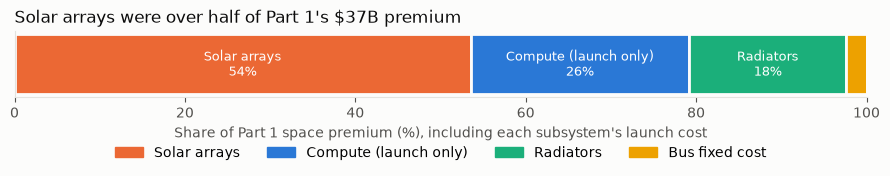

In [6]:
P1 = dict(
    n_sats=1750, alt_km=7000, launch_per_kg=5_453.0, f_sun=0.953,
    m_compute=750.0, m_rad=475.71, m_array=660.0, m_bus=628.57,
    c_compute=2.70e6, c_rad=0.4757e6, c_array=6.60e6, c_bus=0.50e6,
    bus_frac=0.25, avg_compute_kw=114.4,
)
P1["m_total"] = P1["m_compute"] + P1["m_rad"] + P1["m_array"] + P1["m_bus"]
P1["c_launch"] = P1["m_total"] * P1["launch_per_kg"]
gross = 1.0 / (1.0 - P1["bus_frac"])

def p1_row(name, mass, hw):
    launch = mass * gross * P1["launch_per_kg"]
    return {"Subsystem": name, "Mass kg": mass, "Hardware $M": hw / 1e6,
            "Launch share $M": launch / 1e6, "Total $M": (hw + launch) / 1e6}

attr = pd.DataFrame([
    p1_row("Solar arrays", P1["m_array"], P1["c_array"]),
    p1_row("Compute (launch only)", P1["m_compute"], 0.0),
    p1_row("Radiators", P1["m_rad"], P1["c_rad"]),
    {"Subsystem": "Bus fixed cost", "Mass kg": 0.0, "Hardware $M": P1["c_bus"] / 1e6,
     "Launch share $M": 0.0, "Total $M": P1["c_bus"] / 1e6},
])
attr["Share of premium"] = attr["Total $M"] / attr["Total $M"].sum()
P1["premium"] = attr["Total $M"].sum() * 1e6
P1["premium_per_kw_yr"] = P1["premium"] / (P1["avg_compute_kw"] * SATELLITE_LIFE_YR)

display(attr)
print(f"Per-satellite premium: ${P1['premium']/1e6:.2f}M  (Part 1 reported $21.29M)")
print(f"Fleet premium:         ${P1['premium']*P1['n_sats']/1e9:.2f}B (Part 1 reported $37.25B)")
print(f"Per kW-yr of compute over {SATELLITE_LIFE_YR:.0f} yr: ${P1['premium_per_kw_yr']:,.0f}/kW-yr")

fig, ax = plt.subplots(figsize=(9, 2.6))
left = 0.0
colors = [SERIES[1], SERIES[0], SERIES[2], SERIES[3]]
for (_, r), c in zip(attr.iterrows(), colors):
    w = r["Share of premium"] * 100
    ax.barh(0, w, left=left, color=c, edgecolor="#fcfcfb", linewidth=2, height=0.5)
    if w > 6:
        ax.text(left + w / 2, 0, f"{r['Subsystem']}\n{w:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += w
ax.set_xlim(0, 100); ax.set_yticks([]); ax.grid(False)
ax.set_xlabel("Share of Part 1 space premium (%), including each subsystem's launch cost")
ax.set_title("Solar arrays were over half of Part 1's $37B premium", loc="left")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors], labels=list(attr["Subsystem"]),
          loc="upper center", bbox_to_anchor=(0.5, -0.55), ncol=4)
plt.tight_layout(); plt.show()

**Takeaway:** solar arrays were **over half** of Part 1's space premium, even at Part 1's already-optimistic 200 W/kg and \$50/W. Launching the compute module came second. Radiators were under a fifth. So Part 2 focuses on the arrays.

---
## 3. A best-case orbit: 550 km dawn-dusk sun-synchronous

Part 1 went to 7,000 km to escape Earth's shadow. Part 2 starts from the orbit that Google's Suncatcher, and arguably SpaceX's FCC filing, point to instead.

- **Sun-synchronous** means the orbit is tilted slightly past the poles (~97.6°), so Earth's equatorial bulge swings the orbit plane around once per year, in step with the Sun.
- **Dawn-dusk** means the orbit rides the boundary between day and night. The satellite looks down on sunrise or sunset and almost never passes into Earth's shadow.

Why this is the optimistic case:
- **Sunlight nearly all year**, without paying to climb to 7,000 km.
- **Low radiation.** About 150 rad/yr behind 10 mm of aluminum (Suncatcher). At 7,000 km the satellite sits in the inner Van Allen belt.
- **No transfer stage.** Starship drops the satellite close to where it will operate.

### 3.1 Sunlight over the year

Each day of the year we compute the angle between the Sun and the orbit plane, called beta (β), then apply Part 1's cylindrical-shadow model. With β above about 67° at 550 km there is no eclipse at all.

Sun-synchronous inclination at 550 km: 97.58°
Orbital period: 95.5 min;  no-eclipse threshold: |β| > 67.0°
β over the year: 59.0° to 89.9°
Days per year with any eclipse: 98;  worst eclipse: 21.6 min per orbit
Annual average sunlight fraction: 0.9514   (Part 1 at 7,000 km with its beta mix: 0.953)


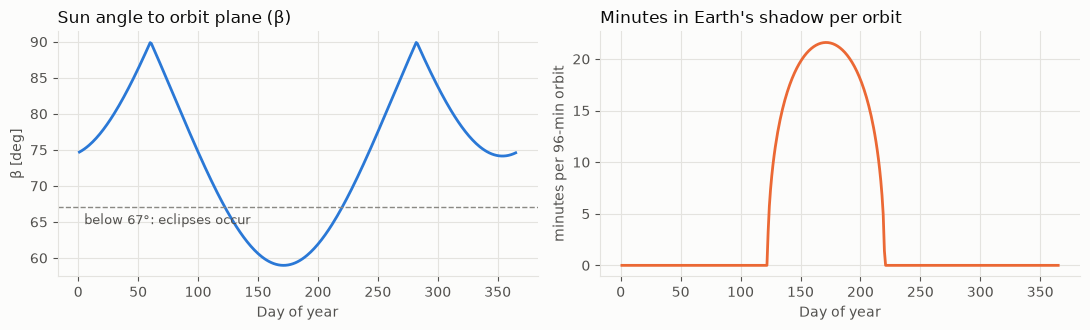

In [7]:
# ---- Functions copied verbatim from Part 1 (space_gpu_datacenter.ipynb, "Core equations") ----
def total_load_w(p_compute_kw: float, overhead_frac: float) -> float:
    """Total electrical load in watts (also treated as heat to reject)."""
    return 1_000.0 * p_compute_kw * (1.0 + overhead_frac)

def orbital_period_s(alt_km: float) -> float:
    r = R_EARTH + 1_000.0 * alt_km
    return 2*np.pi*np.sqrt(r**3 / MU_EARTH)

def sunlight_fraction(alt_km: float, beta_deg: float=0.0) -> float:
    """Fraction of an orbit in sunlight (cylindrical Earth-shadow model). From Part 1."""
    r = R_EARTH + 1_000.0 * alt_km
    beta = np.deg2rad(beta_deg)
    ratio = R_EARTH / r
    if abs(np.sin(beta)) >= ratio:
        return 1.0
    X = (ratio**2 - np.sin(beta)**2) / (np.cos(beta)**2)
    X = np.clip(X, 0.0, 1.0)
    theta_e = np.arcsin(np.sqrt(X))
    return float(1.0 - theta_e/np.pi)

def earth_view_factor_max(alt_km: float) -> float:
    r = R_EARTH + 1_000.0 * alt_km
    return float((R_EARTH / r)**2)

def radiator_area_m2_with_backload(q_internal_w, t_rad_c, alt_km, beta_deg):
    """Part 1's radiator sizing (emitted flux minus absorbed Earth IR, albedo, and residual solar),
    condensed to use the global thermal assumptions. Returns (area_m2, net_flux_w_m2)."""
    t_rad_k = t_rad_c + 273.15
    q_emit = EPSILON * SIGMA * K_EFFECTIVE * (t_rad_k**4 - T_SINK_K**4)
    f_sun = sunlight_fraction(alt_km, beta_deg)
    f_earth = float(np.clip(earth_view_factor_max(alt_km) * EARTH_VIEW_FRACTION_OF_MAX, 0.0, 1.0))
    q_ir = ALPHA_IR * EARTH_IR_FLUX_W_PER_M2 * f_earth
    q_albedo = ALPHA_SOLAR * SOLAR_CONSTANT * EARTH_BOND_ALBEDO * f_earth * ALBEDO_GEOMETRY_FACTOR * f_sun
    q_solar = ALPHA_SOLAR * SOLAR_CONSTANT * RADIATOR_SOLAR_VIEW_FACTOR * f_sun
    q_net = q_emit - (q_ir + q_albedo + q_solar)
    return (np.inf if q_net <= 0 else q_internal_w / q_net), q_net

# ---- New in Part 2: sun-synchronous geometry ----
def sso_inclination_deg(alt_km: float) -> float:
    """Inclination at which J2 precession matches the Sun's yearly motion (360°/365.2422 d)."""
    a = R_EARTH + 1_000.0 * alt_km
    n = math.sqrt(MU_EARTH / a**3)
    omega_dot = 2 * math.pi / (365.2422 * 86_400)
    cos_i = -omega_dot / (1.5 * n * J2 * (R_EARTH / a)**2)
    return math.degrees(math.acos(cos_i))

def sso_beta_deg(day_of_year: float, alt_km: float, ltan_hours: float) -> float:
    """Sun-to-orbit-plane angle for a sun-synchronous orbit with a given local time of ascending node."""
    eps = math.radians(OBLIQUITY_DEG)
    lam = math.radians(360.0 * (day_of_year - 80.0) / 365.2422)       # Sun's ecliptic longitude (0 at ~Mar 21)
    s = np.array([math.cos(lam), math.cos(eps) * math.sin(lam), math.sin(eps) * math.sin(lam)])
    ra_sun = math.atan2(s[1], s[0])
    raan = ra_sun + math.radians(15.0 * (ltan_hours - 12.0))           # node sits (LTAN−12h) east of the Sun
    inc = math.radians(sso_inclination_deg(alt_km))
    n_hat = np.array([math.sin(inc) * math.sin(raan), -math.sin(inc) * math.cos(raan), math.cos(inc)])
    return math.degrees(math.asin(float(np.clip(s @ n_hat, -1, 1))))

INC_DEG = sso_inclination_deg(ALT_KM)
T_ORBIT_MIN = orbital_period_s(ALT_KM) / 60
BETA_CRIT_DEG = math.degrees(math.asin(R_EARTH / (R_EARTH + 1_000 * ALT_KM)))

days = np.arange(1, 366)
betas = np.array([sso_beta_deg(d, ALT_KM, LTAN_HOURS) for d in days])
fsun = np.array([sunlight_fraction(ALT_KM, b) for b in betas])
eclipse_min = (1 - fsun) * T_ORBIT_MIN

F_SUN_ANNUAL = float(fsun.mean())
ECLIPSE_DAYS = int((fsun < 1).sum())

print(f"Sun-synchronous inclination at {ALT_KM:.0f} km: {INC_DEG:.2f}°")
print(f"Orbital period: {T_ORBIT_MIN:.1f} min;  no-eclipse threshold: |β| > {BETA_CRIT_DEG:.1f}°")
print(f"β over the year: {betas.min():.1f}° to {betas.max():.1f}°")
print(f"Days per year with any eclipse: {ECLIPSE_DAYS};  worst eclipse: {eclipse_min.max():.1f} min per orbit")
print(f"Annual average sunlight fraction: {F_SUN_ANNUAL:.4f}   (Part 1 at 7,000 km with its beta mix: 0.953)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(days, betas, color=SERIES[0])
axes[0].axhline(BETA_CRIT_DEG, color=MUTED, lw=1, ls="--")
axes[0].annotate(f"below {BETA_CRIT_DEG:.0f}°: eclipses occur", (5, BETA_CRIT_DEG), xytext=(0, -12),
                 textcoords="offset points", color=INK_2, fontsize=9)
axes[0].set_title("Sun angle to orbit plane (β)", loc="left")
axes[0].set_xlabel("Day of year"); axes[0].set_ylabel("β [deg]")
axes[1].plot(days, eclipse_min, color=SERIES[1])
axes[1].set_title("Minutes in Earth's shadow per orbit", loc="left")
axes[1].set_xlabel("Day of year"); axes[1].set_ylabel(f"minutes per {T_ORBIT_MIN:.0f}-min orbit")
plt.tight_layout(); plt.show()

**Takeaway:** a dawn-dusk orbit is *not* permanently sunlit at 550 km. For about three months around one solstice, the Sun angle drops below the ~67° threshold, and the satellite crosses Earth's shadow on every orbit, for up to ~20 minutes. Under the sunlight-only design (no batteries; compute pauses in shadow), that costs **about 5% of yearly output**. The result is **about the same sunlight as Part 1 got at 7,000 km** (95.3%), but without the expensive climb or the radiation belts.

(Higher dawn-dusk orbits shrink the eclipse season: the shadow threshold drops as altitude rises. Batteries sized for ~20 minutes could also bridge it. Both are possible refinements.)

### 3.2 Radiation (summary; details in `research/part2_research.md`)
- **550 km SSO:** ~150 rad(Si)/yr behind 10 mm Al, so ~750 rad over 5 years. Google's Trillium TPUs showed memory (HBM) irregularities only at ~2 krad and no hard failures up to 15 krad. **GPUs plausibly survive.**
- **Solar cells:** taken optimistically at **1%/yr** power loss for annealing silicon. Solestial lab data showed 96% voltage retained after a 10-year-LEO-equivalent dose.
- **7,000 km:** inner-belt protons that are very hard to shield. Both the GPUs and the arrays become a real problem. This is one of the costs of "going higher" (Section 10).

### 3.3 Drag: why a huge satellite at 550 km can still be cheap to keep up

At 550 km there is still a trace of atmosphere, and a satellite with hundreds of m² of panels would normally feel strong drag. **But in a dawn-dusk orbit, the Sun sits roughly perpendicular to the orbit plane.** So:
- the **solar arrays** face sideways, toward the Sun, and present their thin edge to the direction of travel;
- the **radiators** must be edge-on to the Sun anyway (Part 1's low solar-view factor), so they too can sit in the orbit plane, also edge-on to the velocity.

The only thing pushing into the airflow is roughly the bus and compute module's cross-section. Section 4 compares this with a worst case where the panels face into the airflow. ⚠️ This is my own geometric reasoning; the SolidWorks attitude model will check it.

---
## 4. Sizing one best-case satellite

The satellite carries the same 120 kW compute module as Part 1. What changes:

- **Array** sized for *end-of-life* power: it must still deliver the full load after 5 years at 1%/yr degradation.
- **Radiator** sized at 550 km with Part 1's thermal model, using the fully-sunlit case (highest absorbed heat).
- **No batteries.** Sunlight-only operation, as in Part 1.
- **Station-keeping propellant** for drag over the satellite's life, using electric propulsion.
- **Launch** at Starship \$/kg straight to 550 km, so there is no transfer stage.
- **Bus** still a flat 25% of total mass. The SolidWorks model will replace this.

In [8]:
def drag_dv_per_yr(mass_kg: float, frontal_area_m2: float) -> float:
    """Δv per year to cancel drag [m/s/yr] = drag deceleration × seconds per year."""
    v = math.sqrt(MU_EARTH / (R_EARTH + 1_000 * ALT_KM))
    accel = 0.5 * ATM_DENSITY_KG_M3 * v**2 * DRAG_CD * frontal_area_m2 / mass_kg
    return accel * 365.25 * 86_400

def sso_payload_factor() -> float:
    """Fraction of due-east LEO payload Starship carries to a ~98° sun-synchronous orbit. [EST]
    A due-east launch from 26°N borrows Earth's rotation; a near-polar retrograde launch must
    instead cancel a little of it. The extra Δv is charged to the ship via the rocket equation."""
    v_rot = 465.1 * math.cos(math.radians(LAUNCH_SITE_LAT_DEG))
    sin_az = math.cos(math.radians(INC_DEG)) / math.cos(math.radians(LAUNCH_SITE_LAT_DEG))
    extra_dv = v_rot - v_rot * sin_az                      # lose the eastward boost, plus fight a bit of it
    ve = SHIP_ISP_VAC_S * G0
    p0 = STARSHIP_PAYLOAD_LEO_T
    dv0 = ve * math.log((SHIP_DRY_T + SHIP_PROP_T + p0) / (SHIP_DRY_T + p0))
    ratio = math.exp((dv0 + extra_dv) / ve)
    p1 = (SHIP_DRY_T + SHIP_PROP_T - ratio * SHIP_DRY_T) / (ratio - 1)
    return max(p1, 0.0) / p0, extra_dv

SSO_FACTOR, SSO_EXTRA_DV = sso_payload_factor()


def size_satellite(
    launch_cost_per_kg=LAUNCH_COST_PER_KG,
    array_cost_per_w=ARRAY_COST_PER_W,
    array_w_per_kg=ARRAY_SPECIFIC_POWER_W_PER_KG,
    array_degr_per_yr=ARRAY_DEGRADATION_PER_YR,
    life_yr=SATELLITE_LIFE_YR,
    bus_frac=BUS_MASS_FRACTION_OF_TOTAL,
    frontal_area_m2=FRONTAL_AREA_EDGE_ON_M2,
    apply_sso_penalty=APPLY_SSO_PAYLOAD_PENALTY,
    f_sun=None,
) -> dict:
    """One satellite at 550 km dawn-dusk. Returns masses [kg], costs [$], and premium metrics."""
    f_sun = F_SUN_ANNUAL if f_sun is None else f_sun
    p_load_w = total_load_w(P_COMPUTE_KW, OVERHEAD_FRAC)

    # Solar array: sized so end-of-life power still meets the full load
    eol_factor = (1 - array_degr_per_yr) ** life_yr
    p_array_bol_w = p_load_w / eol_factor
    m_array = p_array_bol_w / array_w_per_kg
    a_array = p_array_bol_w / ARRAY_POWER_DENSITY_W_PER_M2
    c_array = p_array_bol_w * array_cost_per_w

    # Radiator (fully sunlit case = highest absorbed environmental heat)
    a_rad, q_net = radiator_area_m2_with_backload(p_load_w, T_GPU_C - DELTA_T_TO_RADIATOR_C, ALT_KM, 90.0)
    m_rad = a_rad * RADIATOR_AREAL_DENSITY
    c_rad = a_rad * RADIATOR_COST_PER_M2

    # Dry mass with bus, then drag-makeup propellant for the whole life
    m_dry = (M_COMPUTE_KG + m_rad + m_array) / (1 - bus_frac)
    dv_life = drag_dv_per_yr(m_dry, frontal_area_m2) * life_yr
    m_prop = m_dry * (math.exp(dv_life / (G0 * EP_ISP_S)) - 1)
    m_total = m_dry + m_prop

    # Launch
    eff_cost_per_kg = launch_cost_per_kg / (SSO_FACTOR if apply_sso_penalty else 1.0)
    c_launch = m_total * eff_cost_per_kg

    premium = c_array + c_rad + BUS_COST_FIXED + c_launch
    avg_compute_kw = P_COMPUTE_KW * f_sun
    return dict(
        p_load_kw=p_load_w / 1e3, p_array_bol_kw=p_array_bol_w / 1e3, a_array_m2=a_array, a_rad_m2=a_rad,
        m_compute=M_COMPUTE_KG, m_array=m_array, m_rad=m_rad, m_bus=m_dry * bus_frac, m_prop=m_prop, m_total=m_total,
        dv_life=dv_life, eff_cost_per_kg=eff_cost_per_kg,
        c_array=c_array, c_rad=c_rad, c_bus=BUS_COST_FIXED, c_launch=c_launch,
        c_compute=P_COMPUTE_KW * COMPUTE_COST_PER_KW,
        premium=premium, avg_compute_kw=avg_compute_kw,
        premium_per_kw_yr=premium / (avg_compute_kw * life_yr),
        premium_per_w_compute=premium / (avg_compute_kw * 1e3),
        gross=1 / (1 - bus_frac), life_yr=life_yr,
    )

BEST = size_satellite()

def attribution(s: dict) -> pd.DataFrame:
    """Subsystem cost = hardware + launch of its mass (grossed up for its share of the bus)."""
    k = s["gross"] * s["eff_cost_per_kg"]
    rows = [
        ("Solar arrays",          s["m_array"],   s["c_array"]),
        ("Compute (launch only)", s["m_compute"], 0.0),
        ("Radiators",             s["m_rad"],     s["c_rad"]),
    ]
    df = pd.DataFrame([{"Subsystem": n, "Mass kg": m, "Hardware $M": hw / 1e6,
                        "Launch share $M": m * k / 1e6, "Total $M": (hw + m * k) / 1e6} for n, m, hw in rows])
    extra = pd.DataFrame([
        {"Subsystem": "Bus fixed cost", "Mass kg": 0.0, "Hardware $M": s["c_bus"] / 1e6, "Launch share $M": 0.0, "Total $M": s["c_bus"] / 1e6},
        {"Subsystem": "Drag propellant", "Mass kg": s["m_prop"], "Hardware $M": 0.0,
         "Launch share $M": s["m_prop"] * s["eff_cost_per_kg"] / 1e6, "Total $M": s["m_prop"] * s["eff_cost_per_kg"] / 1e6},
    ])
    df = pd.concat([df, extra], ignore_index=True)
    df["Share of premium"] = df["Total $M"] / df["Total $M"].sum()
    return df

print(f"Load {BEST['p_load_kw']:.0f} kW -> array {BEST['p_array_bol_kw']:.1f} kW at beginning of life "
      f"({BEST['a_array_m2']:.0f} m²), radiator {BEST['a_rad_m2']:.0f} m²")
print(f"Satellite mass {BEST['m_total']:,.0f} kg  (Part 1: {P1['m_total']:,.0f} kg)")
print(f"Lifetime drag Δv {BEST['dv_life']:.1f} m/s -> {BEST['m_prop']:.1f} kg propellant")
print(f"Space premium per satellite: ${BEST['premium']/1e6:.2f}M  (Part 1: ${P1['premium']/1e6:.2f}M)")
display(attribution(BEST))

Load 132 kW -> array 138.8 kW at beginning of life (347 m²), radiator 245 m²
Satellite mass 2,581 kg  (Part 1: 2,514 kg)
Lifetime drag Δv 17.4 m/s -> 3.1 kg propellant
Space premium per satellite: $2.64M  (Part 1: $21.29M)


,Subsystem,Mass kg,Hardware $M,Launch share $M,Total $M,Share of premium
0,Solar arrays,694.01,1.39,0.09,1.48,0.56
1,Compute (launch only),750.00,0.00,0.10,0.10,0.04
2,Radiators,489.70,0.49,0.07,0.55,0.21
3,Bus fixed cost,0.00,0.50,0.00,0.50,0.19
4,Drag propellant,3.06,0.00,0.00,0.00,0.00


In [9]:
# Drag sensitivity: edge-on (default) vs. panels facing into the airflow
worst_area = BEST["a_array_m2"] + BEST["a_rad_m2"]
for label, area in [("Edge-on panels (default)", FRONTAL_AREA_EDGE_ON_M2), ("Panels facing the airflow", worst_area)]:
    s = size_satellite(frontal_area_m2=area)
    print(f"{label:28s} frontal {area:6.0f} m²  Δv {s['dv_life']:7.1f} m/s over {SATELLITE_LIFE_YR:.0f} yr  "
          f"propellant {s['m_prop']:6.1f} kg  premium ${s['premium']/1e6:.3f}M")
print("\nDensity at 550 km swings ~10× over the solar cycle; the default uses a near-solar-maximum value. [EST]")

Edge-on panels (default)     frontal     15 m²  Δv    17.4 m/s over 5 yr  propellant    3.1 kg  premium $2.636M
Panels facing the airflow    frontal    592 m²  Δv   688.4 m/s over 5 yr  propellant  123.5 kg  premium $2.648M

Density at 550 km swings ~10× over the solar cycle; the default uses a near-solar-maximum value. [EST]


**Takeaways from the best-case satellite:**
- Moving to 550 km removes Part 1's 2.18× transfer-stage launch penalty. Starship at \$100/kg instead of \$5,453/kg makes **launch nearly disappear from the budget**.
- What remains is **mostly the solar array purchase price**, even at an optimistic \$10/W.
- Drag is negligible *if* the panels fly edge-on. Facing the airflow would cost a few tens of kg of propellant, which is still small at these launch prices.

---
## 5. Fleet and the terrestrial yardstick

**What does "viable" mean?** The space fleet has to beat what the same compute costs on the ground, *excluding the GPUs*, which both sides buy. On the ground you pay for:
- the **building**, with power distribution and cooling, and
- the **electricity**.

We express both in **\$/kW-yr of compute**. Following the optimism principle, the ground side is made as expensive as is defensible:
- an AI-ready build at **\$20M/MW**,
- charged entirely to one **5-year** GPU generation (in reality the building outlasts several),
- electricity at **\$1,500/kW-yr**, the middle of \$570–3,000.

That is generous to space, so we also show a **realistic** ground yardstick: an average US build (\$11.7M/MW) spread over a 15-year building life, plus the same electricity.

In [10]:
def terrestrial_per_kw_yr(build_per_mw=TERRESTRIAL_BUILD_COST_PER_MW,
                          amort_yr=TERRESTRIAL_BUILD_AMORTIZATION_YR,
                          energy=TERRESTRIAL_ENERGY_COST_PER_KW_YR) -> float:
    return build_per_mw / 1_000 / amort_yr + energy

TERR = terrestrial_per_kw_yr()   # optimistic for space
TERR_REAL = terrestrial_per_kw_yr(TERRESTRIAL_REALISTIC_BUILD_COST_PER_MW, TERRESTRIAL_REALISTIC_AMORTIZATION_YR)
TERR_LOW = terrestrial_per_kw_yr(10.7e6, 15, TERRESTRIAL_ENERGY_RANGE_PER_KW_YR[0])
TERR_HIGH = terrestrial_per_kw_yr(20e6, 5, TERRESTRIAL_ENERGY_RANGE_PER_KW_YR[1])

n_sats = math.ceil(TARGET_AVG_COMPUTE_MW * 1_000 / BEST["avg_compute_kw"])
fleet = pd.DataFrame([
    ("Satellites for 200 MW average compute", f"{n_sats:,}", f"{P1['n_sats']:,}"),
    ("Mass per satellite", f"{BEST['m_total']:,.0f} kg", f"{P1['m_total']:,.0f} kg"),
    ("Fleet mass", f"{n_sats*BEST['m_total']/1e3:,.0f} t", f"{P1['n_sats']*P1['m_total']/1e3:,.0f} t"),
    ("Fleet space premium", f"${n_sats*BEST['premium']/1e9:,.1f}B", f"${P1['n_sats']*P1['premium']/1e9:,.1f}B"),
    ("Space premium per kW-yr", f"${BEST['premium_per_kw_yr']:,.0f}", f"${P1['premium_per_kw_yr']:,.0f}"),
    ("Ground yardstick, optimistic for space", f"${TERR:,.0f}", f"${TERR:,.0f}"),
    ("Space ÷ optimistic ground", f"{BEST['premium_per_kw_yr']/TERR:.1f}x", f"{P1['premium_per_kw_yr']/TERR:.1f}x"),
    ("Ground yardstick, realistic", f"${TERR_REAL:,.0f}", f"${TERR_REAL:,.0f}"),
    ("Space ÷ realistic ground", f"{BEST['premium_per_kw_yr']/TERR_REAL:.1f}x", f"{P1['premium_per_kw_yr']/TERR_REAL:.1f}x"),
], columns=["Metric", "Part 2 best case (550 km)", "Part 1 (7,000 km)"])
display(fleet)
print(f"Ground yardstick range: ${TERR_LOW:,.0f}/kW-yr (cheap power, 15-yr building) to "
      f"${TERR_HIGH:,.0f}/kW-yr (expensive power, 5-yr building)")

,Metric,Part 2 best case (550 km),"Part 1 (7,000 km)"
0,Satellites for 200 MW average compute,"1,752","1,750"
1,Mass per satellite,"2,581 kg","2,514 kg"
2,Fleet mass,"4,523 t","4,400 t"
3,Fleet space premium,$4.6B,$37.3B
4,Space premium per kW-yr,"$4,617","$37,213"
5,"Ground yardstick, optimistic for space","$5,500","$5,500"
6,Space ÷ optimistic ground,0.8x,6.8x
7,"Ground yardstick, realistic","$2,280","$2,280"
8,Space ÷ realistic ground,2.0x,16.3x


Ground yardstick range: $1,283/kW-yr (cheap power, 15-yr building) to $7,000/kW-yr (expensive power, 5-yr building)


---
## 6. The staircase: from Part 1 to the best case

Each step changes **one** assumption, so you can see which levers matter. Spending is shown per kW-yr of compute and compared with the ground yardstick.

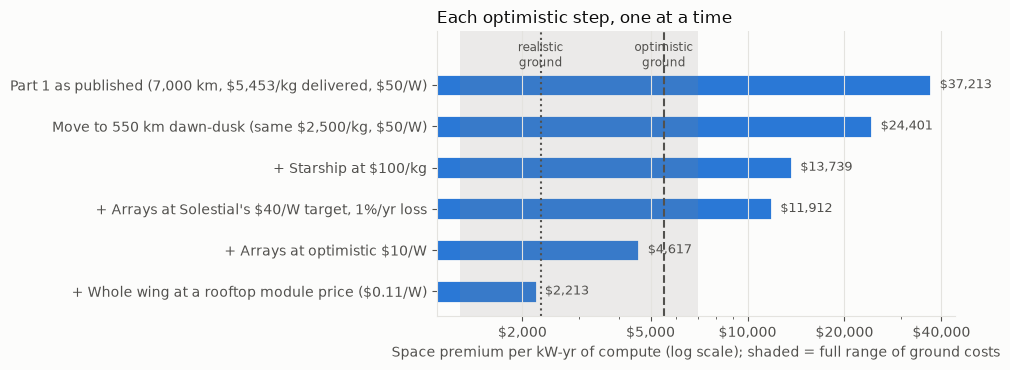

,Step,Premium $/kW-yr,vs optimistic ground,vs realistic ground
0,"Part 1 as published (7,000 km, $5,453/kg deliv...","37,213.41",6.77,16.32
1,"Move to 550 km dawn-dusk (same $2,500/kg, $50/W)","24,400.97",4.44,10.70
2,+ Starship at $100/kg,"13,739.31",2.50,6.03
3,"+ Arrays at Solestial's $40/W target, 1%/yr loss","11,911.64",2.17,5.22
4,+ Arrays at optimistic $10/W,"4,617.30",0.84,2.03
5,+ Whole wing at a rooftop module price ($0.11/W),"2,212.60",0.40,0.97


In [11]:
steps = [
    ("Part 1 as published (7,000 km, $5,453/kg delivered, $50/W)", None),
    ("Move to 550 km dawn-dusk (same $2,500/kg, $50/W)", dict(launch_cost_per_kg=2_500, array_cost_per_w=50, array_degr_per_yr=0)),
    ("+ Starship at $100/kg", dict(array_cost_per_w=50, array_degr_per_yr=0)),
    ("+ Arrays at Solestial's $40/W target, 1%/yr loss", dict(array_cost_per_w=40)),
    ("+ Arrays at optimistic $10/W", dict()),
    ("+ Whole wing at a rooftop module price ($0.11/W)", dict(array_cost_per_w=ROOFTOP_ARRAY_COST_PER_W)),
]
stair = []
for label, kw in steps:
    v = P1["premium_per_kw_yr"] if kw is None else size_satellite(**kw)["premium_per_kw_yr"]
    stair.append((label, v))
stair = pd.DataFrame(stair, columns=["Step", "Premium $/kW-yr"])
stair["vs optimistic ground"] = stair["Premium $/kW-yr"] / TERR
stair["vs realistic ground"] = stair["Premium $/kW-yr"] / TERR_REAL

fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(stair))[::-1]
ax.barh(y, stair["Premium $/kW-yr"], color=SERIES[0], height=0.55, edgecolor="#fcfcfb", linewidth=2)
for yi, v in zip(y, stair["Premium $/kW-yr"]):
    ax.annotate(f"${v:,.0f}", (v, yi), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
ax.axvspan(TERR_LOW, TERR_HIGH, color=MUTED, alpha=0.15, lw=0)
for xv, ls, txt in [(TERR, "--", "optimistic\nground"), (TERR_REAL, ":", "realistic\nground")]:
    ax.axvline(xv, color=INK_2, lw=1.5, ls=ls)
    ax.annotate(txt, (xv, y.max() + 0.35), fontsize=8.5, color=INK_2, ha="center", va="bottom")
ax.set_ylim(-0.6, y.max() + 1.3)
ax.set_xscale("log")
ax.set_yticks(y, stair["Step"])
ax.xaxis.set_major_locator(mticker.FixedLocator([1_000, 2_000, 5_000, 10_000, 20_000, 40_000]))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlabel("Space premium per kW-yr of compute (log scale); shaded = full range of ground costs")
ax.set_title("Each optimistic step, one at a time", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
display(stair)

**How to read the staircase:**
- Moving to 550 km and getting Starship-class launch takes out roughly two-thirds of the gap. **Launch was Part 1's biggest bill, and the orbit and Starship fix it.**
- After that, **the array price is the lever that's left**. At Solestial's \$40/W target, space still costs ~2× even the space-friendly yardstick, and ~5× the realistic one.
- At \$10/W, space beats the space-friendly yardstick but still costs ~2× the realistic one.
- **Only with the whole wing at rooftop prices does space roughly tie the realistic ground yardstick.** Matching a normal datacenter takes array prices ~100× below today's cheapest flight panel (see 1.4).
- With the array nearly free, what remains is the radiators (\$2,000/m²) and the bus (\$0.5M per satellite). **Both are Part 1 placeholders**, and they now decide the answer. They need real sources (open item).

---
## 7. Launch price sweep across array technologies

How does the space premium change as Starship pricing falls, for each class of solar array? Each line is one array technology, from heritage satellite hardware to the rooftop-price bookend. The flat lines at the left show the array price setting a floor that cheaper launch can't break through.

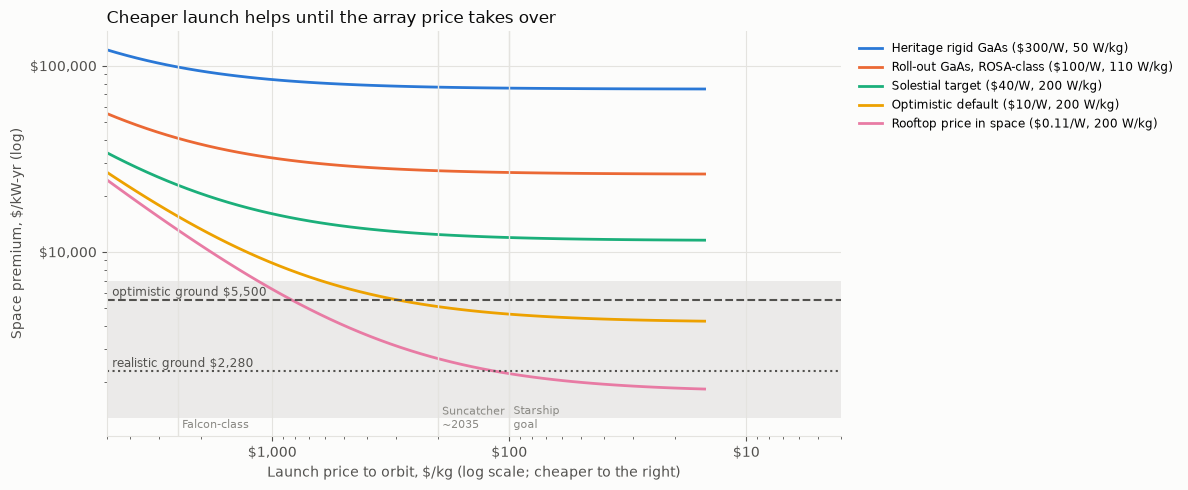

In [12]:
TIERS = [
    ("Heritage rigid GaAs ($300/W, 50 W/kg)", 300.0, 50.0),
    ("Roll-out GaAs, ROSA-class ($100/W, 110 W/kg)", 100.0, 110.0),
    ("Solestial target ($40/W, 200 W/kg)", 40.0, 200.0),
    ("Optimistic default ($10/W, 200 W/kg)", 10.0, 200.0),
    ("Rooftop price in space ($0.11/W, 200 W/kg)", ROOFTOP_ARRAY_COST_PER_W, 200.0),
]
launch_grid = np.logspace(np.log10(15), np.log10(5_000), 60)

fig, ax = plt.subplots(figsize=(12, 5))
for (name, cpw, wpk), color in zip(TIERS, SERIES):
    vals = [size_satellite(launch_cost_per_kg=L, array_cost_per_w=cpw, array_w_per_kg=wpk)["premium_per_kw_yr"]
            for L in launch_grid]
    ax.plot(launch_grid, vals, color=color, label=name)
ax.axhspan(TERR_LOW, TERR_HIGH, color=MUTED, alpha=0.15, lw=0)
for yv, ls, txt in [(TERR, "--", f"optimistic ground ${TERR:,.0f}"), (TERR_REAL, ":", f"realistic ground ${TERR_REAL:,.0f}")]:
    ax.axhline(yv, color=INK_2, lw=1.5, ls=ls)
    ax.annotate(txt, (5_000, yv), xytext=(4, 3), textcoords="offset points", ha="left", fontsize=8.5, color=INK_2)
for L, txt in [(2_500, "Falcon-class"), (200, "Suncatcher\n~2035"), (100, "Starship\ngoal")]:
    ax.axvline(L, color=GRID, lw=1)
    ax.annotate(txt, (L, 0.02), xycoords=ax.get_xaxis_transform(), xytext=(3, 0),
                textcoords="offset points", fontsize=8, color=MUTED)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(4, 5_000)
ax.invert_xaxis()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlabel("Launch price to orbit, $/kg (log scale; cheaper to the right)")
ax.set_ylabel("Space premium, $/kW-yr (log)")
ax.set_title("Cheaper launch helps until the array price takes over", loc="left")
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8.5)
plt.tight_layout(); plt.show()

---
## 8. What would have to be true: the break-even array price

For any launch price and array weight (W/kg), there is a **maximum array price (\$/W)** at which the space fleet exactly matches the ground yardstick. The premium is linear in array price, so this can be solved exactly:

```
break-even $/W = (ground yardstick × compute kW × life  −  everything except the array hardware)
                 ÷ array watts at beginning of life
```

A negative result means **even a free array wouldn't break even** at that launch price and weight.

In [13]:
def breakeven_array_cost_per_w(target_per_kw_yr=None, **kw) -> float:
    target = TERR if target_per_kw_yr is None else target_per_kw_yr
    s0 = size_satellite(array_cost_per_w=0.0, **kw)
    budget = target * s0["avg_compute_kw"] * s0["life_yr"]
    return (budget - s0["premium"]) / (s0["p_array_bol_kw"] * 1e3)

launch_pts = [2_500, 1_000, 500, 200, 100, 50, 20]
wpk_pts = [50, 110, 200, 300]
be = pd.DataFrame(
    {f"{w} W/kg": [breakeven_array_cost_per_w(launch_cost_per_kg=L, array_w_per_kg=w) for L in launch_pts] for w in wpk_pts},
    index=pd.Index([f"${L:,}/kg" for L in launch_pts], name="Launch price"),
)
print(f"Break-even array price, $/W (ground yardstick ${TERR:,.0f}/kW-yr; negative = no array price works)")
display(be)

# Sensitivity: the same table against the range of ground costs, at 200 W/kg
sens = pd.DataFrame({
    "Cheap ground": [breakeven_array_cost_per_w(TERR_LOW, launch_cost_per_kg=L) for L in launch_pts],
    "Realistic ground": [breakeven_array_cost_per_w(TERR_REAL, launch_cost_per_kg=L) for L in launch_pts],
    "Optimistic-for-space ground": [breakeven_array_cost_per_w(TERR, launch_cost_per_kg=L) for L in launch_pts],
    "Expensive ground": [breakeven_array_cost_per_w(TERR_HIGH, launch_cost_per_kg=L) for L in launch_pts],
}, index=be.index)
print(f"\nBreak-even $/W at 200 W/kg vs. ground cost (${TERR_LOW:,.0f} / ${TERR_REAL:,.0f} / ${TERR:,.0f} / ${TERR_HIGH:,.0f} per kW-yr)")
display(sens)

Break-even array price, $/W (ground yardstick $5,500/kW-yr; negative = no array price works)


,50 W/kg,110 W/kg,200 W/kg,300 W/kg
Launch price,,,,
"$2,500/kg",-81.00,-44.64,-31.00,-25.45
"$1,000/kg",-23.11,-8.56,-3.11,-0.88
$500/kg,-3.81,3.46,6.19,7.30
$200/kg,7.77,10.68,11.77,12.22
$100/kg,11.63,13.08,13.63,13.85
$50/kg,13.56,14.29,14.56,14.67
$20/kg,14.72,15.01,15.12,15.16



Break-even $/W at 200 W/kg vs. ground cost ($1,283 / $2,280 / $5,500 / $7,000 per kW-yr)


,Cheap ground,Realistic ground,Optimistic-for-space ground,Expensive ground
Launch price,,,,
"$2,500/kg",-48.35,-44.25,-31.00,-24.83
"$1,000/kg",-20.45,-16.35,-3.11,3.06
$500/kg,-11.15,-7.05,6.19,12.36
$200/kg,-5.57,-1.47,11.77,17.94
$100/kg,-3.71,0.39,13.63,19.80
$50/kg,-2.78,1.32,14.56,20.73
$20/kg,-2.22,1.87,15.12,21.29


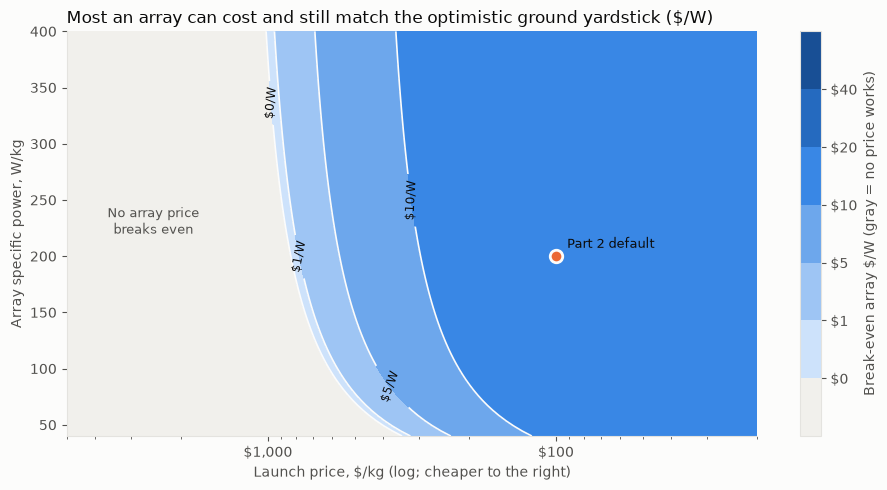

In [14]:
L_grid = np.logspace(np.log10(20), np.log10(5_000), 80)
W_grid = np.linspace(40, 400, 80)
Z = np.array([[breakeven_array_cost_per_w(launch_cost_per_kg=L, array_w_per_kg=w) for L in L_grid] for w in W_grid])

fig, ax = plt.subplots(figsize=(9.5, 5))
levels = [0, 1, 5, 10, 20, 40]
ramp = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95"]
cf = ax.contourf(L_grid, W_grid, Z, levels=[-1e9] + levels + [1e9], colors=["#f1f0ec"] + ramp, extend="neither")
cs = ax.contour(L_grid, W_grid, Z, levels=levels, colors="#fcfcfb", linewidths=1.2)
ax.clabel(cs, fmt=lambda v: f"${v:g}/W", fontsize=8.5, colors=INK)
ax.plot(LAUNCH_COST_PER_KG, ARRAY_SPECIFIC_POWER_W_PER_KG, "o", color=SERIES[1], ms=9, mec="#fcfcfb", mew=2)
ax.annotate("Part 2 default", (LAUNCH_COST_PER_KG, ARRAY_SPECIFIC_POWER_W_PER_KG), xytext=(8, 6),
            textcoords="offset points", fontsize=9, color=INK)
ax.set_xscale("log"); ax.invert_xaxis()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlabel("Launch price, $/kg (log; cheaper to the right)")
ax.set_ylabel("Array specific power, W/kg")
ax.set_title("Most an array can cost and still match the optimistic ground yardstick ($/W)", loc="left")
ax.text(2_500, 220, "No array price\nbreaks even", color=INK_2, fontsize=9, ha="center")
ax.grid(False)
cbar = fig.colorbar(cf, ax=ax, ticks=levels)
cbar.ax.set_yticklabels([f"${v}" for v in levels]); cbar.set_label("Break-even array $/W (gray = no price works)")
plt.tight_layout(); plt.show()

**How to read the break-even map:** each colored band is a ceiling on what the **whole deployed array** can cost per watt. Moving right (cheaper launch) or up (lighter arrays) raises the ceiling, but it levels off: once launch is nearly free, the ceiling is set by the ground yardstick minus radiators and bus.

Compare the ceiling at the Part 2 default point with the price ladder in Section 1.3. That comparison is the headline for the post:
- Against the **space-friendly** yardstick, at \$100/kg, the whole array can cost about **\$13–14/W**. That is just above Starpath's \$11.20/W flight panel and well below Solestial's \$40/W target.
- Against the **realistic** yardstick, the ceiling falls to **well under \$1/W**, only a few times above a rooftop module's price. **Everything hinges on which ground cost you believe, and on array prices falling ~30–100×.**

---
## 9. Fitting into Starship

Starship sells *flights*, not kilograms. \$/kg only holds if every flight leaves full, so we check how many satellites fit by **mass**. Fit by **volume** waits for the SolidWorks model, which gives the stowed size. Optimistic payload is 150 t to orbit.

Getting to a near-polar sun-synchronous orbit costs payload: a due-east launch borrows Earth's rotation, while a ~98° launch slightly fights it. The estimate below charges that extra speed to Starship's upper stage through the rocket equation. ⚠️ This is a rough estimate; no official Starship SSO figure has been published.

In [15]:
payload_sso_t = STARSHIP_PAYLOAD_LEO_T * SSO_FACTOR
sats_per_flight_leo = int(STARSHIP_PAYLOAD_LEO_T * 1_000 // BEST["m_total"])
sats_per_flight_sso = int(payload_sso_t * 1_000 // BEST["m_total"])
flight_price = LAUNCH_COST_PER_KG * STARSHIP_PAYLOAD_LEO_T * 1_000

print(f"Extra Δv to reach {INC_DEG:.1f}° from {LAUNCH_SITE_LAT_DEG:.0f}°N: ~{SSO_EXTRA_DV:,.0f} m/s  [EST]")
print(f"Starship payload: {STARSHIP_PAYLOAD_LEO_T:.0f} t due-east  ->  ~{payload_sso_t:.0f} t to SSO ({SSO_FACTOR:.0%})")
print(f"Implied flight price at ${LAUNCH_COST_PER_KG:,.0f}/kg x {STARSHIP_PAYLOAD_LEO_T:.0f} t: ${flight_price/1e6:,.0f}M")
print(f"Satellites per flight (mass-limited): {sats_per_flight_leo} if due-east capacity, {sats_per_flight_sso} to SSO")
print(f"Flights for {n_sats:,} satellites: {math.ceil(n_sats/sats_per_flight_sso):,} (SSO)")
s_pen = size_satellite(apply_sso_penalty=True)
print(f"Premium with the SSO payload penalty applied: ${s_pen['premium_per_kw_yr']:,.0f}/kW-yr "
      f"(vs ${BEST['premium_per_kw_yr']:,.0f} without)")
print(f"\nVolume check (pending CAD): {STARSHIP_BAY_VOLUME_M3:,.0f} m³ bay / {sats_per_flight_sso} sats = "
      f"{STARSHIP_BAY_VOLUME_M3/max(sats_per_flight_sso,1):.0f} m³ each, to hold a stowed "
      f"{BEST['a_array_m2']:.0f} m² array + {BEST['a_rad_m2']:.0f} m² radiator + compute module")

Extra Δv to reach 97.6° from 26°N: ~479 m/s  [EST]
Starship payload: 150 t due-east  ->  ~113 t to SSO (75%)
Implied flight price at $100/kg x 150 t: $15M
Satellites per flight (mass-limited): 58 if due-east capacity, 43 to SSO
Flights for 1,752 satellites: 41 (SSO)
Premium with the SSO payload penalty applied: $4,767/kW-yr (vs $4,617 without)

Volume check (pending CAD): 1,000 m³ bay / 43 sats = 23 m³ each, to hold a stowed 347 m² array + 245 m² radiator + compute module


---
## 10. Summary and what comes next

In [16]:
L_DEFAULT = LAUNCH_COST_PER_KG
be_default = breakeven_array_cost_per_w()
print("=== Part 2 best case: 550 km dawn-dusk, Starship, optimistic arrays ===")
print(f"Satellites for 200 MW:        {n_sats:,}  ({BEST['m_total']:,.0f} kg each)")
print(f"Fleet space premium:          ${n_sats*BEST['premium']/1e9:,.1f}B   (Part 1: $37.3B)")
print(f"Premium per kW-yr:            ${BEST['premium_per_kw_yr']:,.0f}")
print(f"   vs optimistic ground ${TERR:,.0f} -> {BEST['premium_per_kw_yr']/TERR:.1f}x;  vs realistic ground ${TERR_REAL:,.0f} -> {BEST['premium_per_kw_yr']/TERR_REAL:.1f}x")
att = attribution(BEST).set_index("Subsystem")["Share of premium"]
print(f"Array share of premium:       {att['Solar arrays']:.0%}")
print(f"Break-even array price at ${L_DEFAULT:,.0f}/kg, {ARRAY_SPECIFIC_POWER_W_PER_KG:.0f} W/kg: "
      f"${be_default:,.2f}/W (optimistic ground), ${breakeven_array_cost_per_w(TERR_REAL):,.2f}/W (realistic ground)")
print(f"   vs. today's cheapest space-rated panel $11.20/W, Solestial target $40/W, flight arrays $75–250/W")

=== Part 2 best case: 550 km dawn-dusk, Starship, optimistic arrays ===
Satellites for 200 MW:        1,752  (2,581 kg each)
Fleet space premium:          $4.6B   (Part 1: $37.3B)
Premium per kW-yr:            $4,617
   vs optimistic ground $5,500 -> 0.8x;  vs realistic ground $2,280 -> 2.0x
Array share of premium:       56%
Break-even array price at $100/kg, 200 W/kg: $13.63/W (optimistic ground), $0.39/W (realistic ground)
   vs. today's cheapest space-rated panel $11.20/W, Solestial target $40/W, flight arrays $75–250/W


### Why might we still need a higher orbit? (outline for the post)
550 km dawn-dusk is the best case on cost. Reasons a real system might go higher anyway:
1. **One orbital plane.** Every satellite sits over the dawn/dusk line, so all traffic routes through laser links to whichever satellites are near the user. The Part 1 beta mix assumed many planes for coverage.
2. **Crowding.** 550 km is Starlink's neighborhood. Thousands of 500+ m² satellites add collision and debris risk, and SpaceX's own FCC filing spans 500–2,000 km.
3. **Drag over the solar cycle.** Cheap only if the panels stay edge-on; solar maximum raises density ~10×.
4. **Eclipse season** costs a little output each year. Higher orbits shorten it, but climbing brings radiation and transfer costs (Part 1).

### Next: the SolidWorks model
Inputs it will take from this notebook: array area, radiator area, compute module size. Outputs that come back:
- a **bottom-up bus mass** to replace the flat 25%,
- **stowed volume**, giving satellites per Starship by volume,
- **mass properties** to size attitude control and check the edge-on drag assumption.

### Open items
- SPENVIS radiation runs for 550 km SSO vs. 7,000 km (solar cell loss, GPU dose).
- Real sources for radiator hardware cost (\$2,000/m² placeholder) and bus cost (\$0.5M placeholder). With cheap arrays, these decide the answer.
- A density value at 550 km over the solar cycle (NRLMSIS).
- An official Starship SSO payload figure.